<a href="https://colab.research.google.com/github/Oleksandr-123/practice-1/blob/main/notebooks/PR02_Oleksandr_Maslak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота №2
## Дослідницький аналіз і підготовка даних

**Студент:** Маслак Олександр

**Група:** ІН-42/1

**Варіант:** 12

**Дата виконання:** 17.11.2026

### Мета роботи

Навчитися аналізувати якість табличних даних, виявляти та виправляти пропуски, дублікати, неправильні типи й аномальні значення, кодувати категоріальні ознаки та формувати навчальну і тестову вибірки.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


In [2]:
PROJECT_DIR = Path("/content/pattern-recognition-practice")

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

SOURCE_PATH = DATA_DIR / "iris.csv"
DIRTY_PATH = DATA_DIR / "iris_dirty.csv"
CLEANED_PATH = PROCESSED_DIR / "iris_cleaned.csv"

X_TRAIN_PATH = PROCESSED_DIR / "X_train.csv"
X_TEST_PATH = PROCESSED_DIR / "X_test.csv"
Y_TRAIN_PATH = PROCESSED_DIR / "y_train.csv"
Y_TEST_PATH = PROCESSED_DIR / "y_test.csv"

SUMMARY_PATH = REPORTS_DIR / "preprocessing_summary.csv"
CLASS_MAPPING_PATH = REPORTS_DIR / "class_mapping.json"

for folder in [DATA_DIR, PROCESSED_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Папки успешно созданы")

Папки успешно созданы


In [3]:
iris = load_iris(as_frame=True)

source_df = iris.frame.copy()

source_df["species"] = source_df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

source_df = source_df.drop(columns=["target"])

source_df = source_df.rename(columns={
    "sepal length (cm)": "sepal_length_cm",
    "sepal width (cm)": "sepal_width_cm",
    "petal length (cm)": "petal_length_cm",
    "petal width (cm)": "petal_width_cm"
})

source_df.to_csv(SOURCE_PATH, index=False)

print("Размер датасета:", source_df.shape)
display(source_df.head())

Размер датасета: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
rng = np.random.default_rng(42)

dirty_df = source_df.copy()

dirty_df["measurement_device"] = rng.choice(
    ["device_a", "device_b", "device_c"],
    size=len(dirty_df),
    p=[0.40, 0.35, 0.25]
)

missing_plan = {
    "sepal_length_cm": 4,
    "sepal_width_cm": 5,
    "petal_length_cm": 4,
    "petal_width_cm": 5,
    "measurement_device": 4,
    "species": 2
}

for column, count in missing_plan.items():
    rows = rng.choice(dirty_df.index, size=count, replace=False)
    dirty_df.loc[rows, column] = np.nan

dirty_df["sepal_length_cm"] = dirty_df["sepal_length_cm"].astype("object")

dirty_df.loc[0, "sepal_length_cm"] = "5,1"
dirty_df.loc[1, "sepal_length_cm"] = "unknown"
dirty_df.loc[2, "sepal_length_cm"] = " 6.3 "

dirty_df.loc[3, "measurement_device"] = " Device_A "
dirty_df.loc[4, "measurement_device"] = "DEVICE_B"
dirty_df.loc[5, "measurement_device"] = "device c"

dirty_df.loc[10, "petal_length_cm"] = -1.0
dirty_df.loc[20, "sepal_width_cm"] = 18.0
dirty_df.loc[30, "petal_width_cm"] = 9.5

dirty_df = pd.concat([
    dirty_df,
    dirty_df.iloc[[6, 27, 50, 88]]
], ignore_index=True)

dirty_df.to_csv(DIRTY_PATH, index=False)

raw_df = pd.read_csv(DIRTY_PATH)

print("Розмір забрудненого набору даних:", raw_df.shape)
display(raw_df.head(10))

Розмір забрудненого набору даних: (154, 6)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,"5,1",3.5,1.4,0.2,setosa,device_c
1,unknown,3.0,1.4,0.2,setosa,device_b
2,6.3,3.2,1.3,0.2,setosa,device_c
3,4.6,3.1,1.5,0.2,setosa,Device_A
4,5.0,3.6,1.4,0.2,setosa,DEVICE_B
5,5.4,3.9,1.7,NaN,setosa,device c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,device_c
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


In [6]:
print("Перші 5 рядків:")
display(raw_df.head())

print("Останні 5 рядків:")
display(raw_df.tail())

print("Інформація про набір даних:")
raw_df.info()

quality_report = pd.DataFrame({
    "data_type": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2),
    "unique_count": raw_df.nunique()
})

print("Звіт про якість даних:")
display(quality_report)

Перші 5 рядків:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,"5,1",3.5,1.4,0.2,setosa,device_c
1,unknown,3.0,1.4,0.2,setosa,device_b
2,6.3,3.2,1.3,0.2,setosa,device_c
3,4.6,3.1,1.5,0.2,setosa,Device_A
4,5.0,3.6,1.4,0.2,setosa,DEVICE_B


Останні 5 рядків:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
149,5.9,3.0,5.1,1.8,virginica,device_a
150,4.6,3.4,1.4,0.3,setosa,device_c
151,5.2,3.5,1.5,0.2,setosa,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a


Інформація про набір даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     151 non-null    object 
 1   sepal_width_cm      149 non-null    float64
 2   petal_length_cm     150 non-null    float64
 3   petal_width_cm      149 non-null    float64
 4   species             152 non-null    object 
 5   measurement_device  150 non-null    object 
dtypes: float64(3), object(3)
memory usage: 7.3+ KB
Звіт про якість даних:


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,3,1.95,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6


Кількість пропущених значень:


,missing_count,missing_percent
sepal_length_cm,3,1.95
sepal_width_cm,5,3.25
petal_length_cm,4,2.60
petal_width_cm,5,3.25
species,2,1.30
measurement_device,4,2.60


Кількість пропусків за стовпцями:


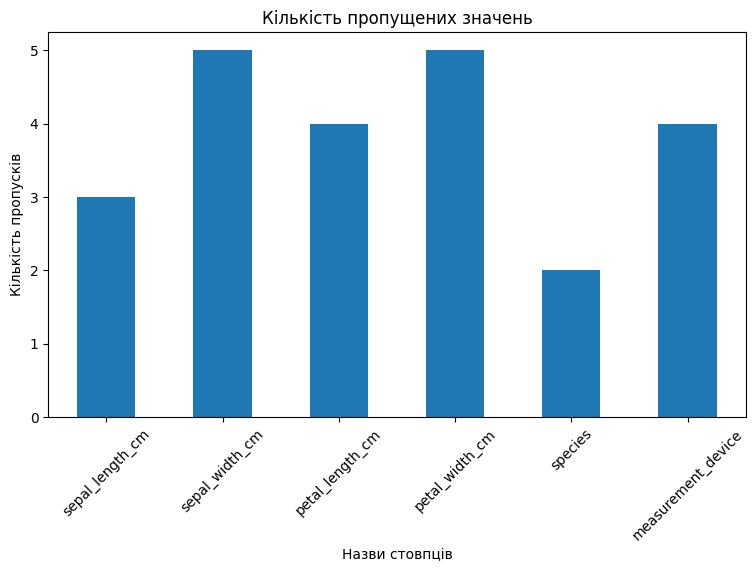

In [7]:
missing_report = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2)
})

print("Кількість пропущених значень:")
display(missing_report)

print("Кількість пропусків за стовпцями:")

missing_report["missing_count"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Кількість пропущених значень")
plt.xlabel("Назви стовпців")
plt.ylabel("Кількість пропусків")
plt.xticks(rotation=45)
plt.show()

In [8]:
duplicate_mask = raw_df.duplicated(keep=False)

duplicate_count = raw_df.duplicated().sum()

print("Кількість повторюваних рядків:", duplicate_count)

print("Усі рядки, що мають дублікати:")
display(raw_df[duplicate_mask])

Кількість повторюваних рядків: 4
Усі рядки, що мають дублікати:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
6,4.6,3.4,1.4,0.3,setosa,device_c
27,5.2,3.5,1.5,0.2,setosa,device_a
50,7.0,3.2,4.7,1.4,versicolor,device_a
88,5.6,3.0,4.1,1.3,versicolor,device_a
150,4.6,3.4,1.4,0.3,setosa,device_c
151,5.2,3.5,1.5,0.2,setosa,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a


In [9]:
numeric_columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

print("Типи даних числових стовпців:")
display(raw_df[numeric_columns].dtypes)

prepared_values = (
    raw_df["sepal_length_cm"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False)
)

converted_values = pd.to_numeric(
    prepared_values,
    errors="coerce"
)

invalid_values = raw_df.loc[
    converted_values.isna() & raw_df["sepal_length_cm"].notna(),
    "sepal_length_cm"
]

print("Некоректні значення у стовпці sepal_length_cm:")
display(invalid_values)

Типи даних числових стовпців:


,0
sepal_length_cm,object
sepal_width_cm,float64
petal_length_cm,float64
petal_width_cm,float64


Некоректні значення у стовпці sepal_length_cm:


,sepal_length_cm
1,unknown


In [10]:
print("Унікальні значення measurement_device:")

for value in raw_df["measurement_device"].unique():
    print(repr(value))

print("\nКількість кожної категорії:")

device_counts_raw = raw_df["measurement_device"].value_counts(
    dropna=False
)

display(device_counts_raw)

print("Унікальні значення species:")
display(raw_df["species"].value_counts(dropna=False))

Унікальні значення measurement_device:
'device_c'
'device_b'
' Device_A '
'DEVICE_B'
'device c'
'device_a'
nan

Кількість кожної категорії:


,count
measurement_device,
device_b,58
device_a,57
device_c,32
NaN,4
Device_A,1
device c,1
DEVICE_B,1


Унікальні значення species:


,count
species,
setosa,52
versicolor,51
virginica,49
NaN,2


In [11]:
clean_df = raw_df.drop_duplicates().copy()

clean_df = clean_df.reset_index(drop=True)

print("Кількість рядків до видалення дублікатів:", len(raw_df))
print("Кількість рядків після видалення дублікатів:", len(clean_df))
print("Кількість видалених дублікатів:", len(raw_df) - len(clean_df))

Кількість рядків до видалення дублікатів: 154
Кількість рядків після видалення дублікатів: 150
Кількість видалених дублікатів: 4


In [12]:
for column in numeric_columns:
    clean_df[column] = (
        clean_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

print("Типи даних після перетворення:")
display(clean_df[numeric_columns].dtypes)

print("Кількість пропущених значень:")
display(clean_df[numeric_columns].isna().sum())

Типи даних після перетворення:


,0
sepal_length_cm,Float64
sepal_width_cm,Float64
petal_length_cm,Float64
petal_width_cm,Float64


Кількість пропущених значень:


,0
sepal_length_cm,4
sepal_width_cm,5
petal_length_cm,4
petal_width_cm,5


In [13]:
clean_df["measurement_device"] = (
    clean_df["measurement_device"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

clean_df["species"] = (
    clean_df["species"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_species = ["setosa", "versicolor", "virginica"]

clean_df.loc[
    ~clean_df["species"].isin(valid_species),
    "species"
] = pd.NA

print("Унікальні значення measurement_device:")
display(clean_df["measurement_device"].value_counts(dropna=False))

print("Унікальні значення species:")
display(clean_df["species"].value_counts(dropna=False))

Унікальні значення measurement_device:


,count
measurement_device,
device_b,59
device_a,55
device_c,32
<NA>,4


Унікальні значення species:


,count
species,
setosa,50
versicolor,49
virginica,49
<NA>,2


In [14]:
rows_before = len(clean_df)

clean_df = clean_df.dropna(subset=["species"]).copy()
clean_df = clean_df.reset_index(drop=True)

print("Кількість видалених рядків:", rows_before - len(clean_df))
print("Кількість рядків після видалення:", len(clean_df))

Кількість видалених рядків: 2
Кількість рядків після видалення: 148


In [15]:
anomaly_masks = {}
anomaly_counts = {}

for column in numeric_columns:
    q1 = clean_df[column].quantile(0.25)
    q3 = clean_df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 3 * iqr
    upper_bound = q3 + 3 * iqr

    iqr_mask = (
        (clean_df[column] < lower_bound) |
        (clean_df[column] > upper_bound)
    )

    impossible_mask = clean_df[column] <= 0

    anomaly_mask = iqr_mask | impossible_mask

    anomaly_masks[column] = anomaly_mask
    anomaly_counts[column] = int(anomaly_mask.sum())

    print("Стовпець:", column)
    print("Кількість аномалій:", anomaly_counts[column])

print("\nЗагальна кількість аномалій:")
print(sum(anomaly_counts.values()))

Стовпець: sepal_length_cm
Кількість аномалій: 0
Стовпець: sepal_width_cm
Кількість аномалій: 1
Стовпець: petal_length_cm
Кількість аномалій: 1
Стовпець: petal_width_cm
Кількість аномалій: 1

Загальна кількість аномалій:
3


In [16]:
for column, mask in anomaly_masks.items():
    clean_df.loc[mask, column] = np.nan

print("Кількість пропущених значень після обробки аномалій:")
display(clean_df[numeric_columns].isna().sum())

Кількість пропущених значень після обробки аномалій:


,0
sepal_length_cm,4
sepal_width_cm,6
petal_length_cm,5
petal_width_cm,6


In [17]:
for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

clean_df["measurement_device"] = clean_df["measurement_device"].fillna(
    clean_df["measurement_device"].mode()[0]
)

print("Кількість пропусків після заповнення:")
display(clean_df.isna().sum())

Кількість пропусків після заповнення:


,0
sepal_length_cm,0
sepal_width_cm,0
petal_length_cm,0
petal_width_cm,0
species,0
measurement_device,0


In [18]:
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

print("Розмір очищеного набору даних:", clean_df.shape)

clean_quality_report = pd.DataFrame({
    "data_type": clean_df.dtypes.astype(str),
    "missing_count": clean_df.isna().sum(),
    "unique_count": clean_df.nunique()
})

print("Звіт про якість очищених даних:")
display(clean_quality_report)

print("Кількість дублікатів:", clean_df.duplicated().sum())

Розмір очищеного набору даних: (148, 6)
Звіт про якість очищених даних:


,data_type,missing_count,unique_count
sepal_length_cm,Float64,0,35
sepal_width_cm,Float64,0,23
petal_length_cm,Float64,0,42
petal_width_cm,Float64,0,22
species,string,0,3
measurement_device,string,0,3


Кількість дублікатів: 0


In [19]:
print("Описова статистика числових ознак:")
display(clean_df[numeric_columns].describe())

Описова статистика числових ознак:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,148.0,148.0,148.0,148.0
mean,5.841216,3.046622,3.731081,1.212162
std,0.805671,0.423528,1.739843,0.73982
min,4.3,2.0,1.0,0.1
25%,5.1,2.8,1.6,0.3
50%,5.8,3.0,4.3,1.3
75%,6.4,3.3,5.025,1.8
max,7.9,4.4,6.9,2.5


In [20]:
mean_median_comparison = pd.DataFrame({
    "mean": clean_df[numeric_columns].mean(),
    "median": clean_df[numeric_columns].median()
})

mean_median_comparison["difference"] = (
    mean_median_comparison["mean"] -
    mean_median_comparison["median"]
)

print("Порівняння середнього значення та медіани:")
display(mean_median_comparison.round(3))

Порівняння середнього значення та медіани:


,mean,median,difference
sepal_length_cm,5.841,5.8,0.041
sepal_width_cm,3.047,3.0,0.047
petal_length_cm,3.731,4.3,-0.569
petal_width_cm,1.212,1.3,-0.088


Розподіл класів:


,count
species,
setosa,50
versicolor,49
virginica,49


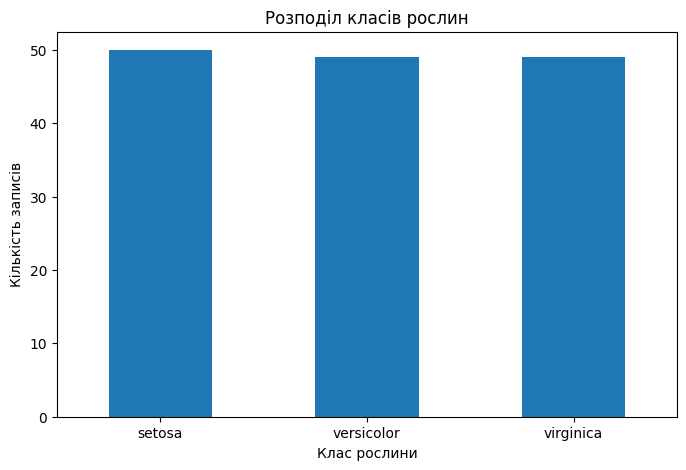

In [21]:
class_distribution = clean_df["species"].value_counts()

print("Розподіл класів:")
display(class_distribution)

class_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Розподіл класів рослин")
plt.xlabel("Клас рослини")
plt.ylabel("Кількість записів")
plt.xticks(rotation=0)
plt.show()

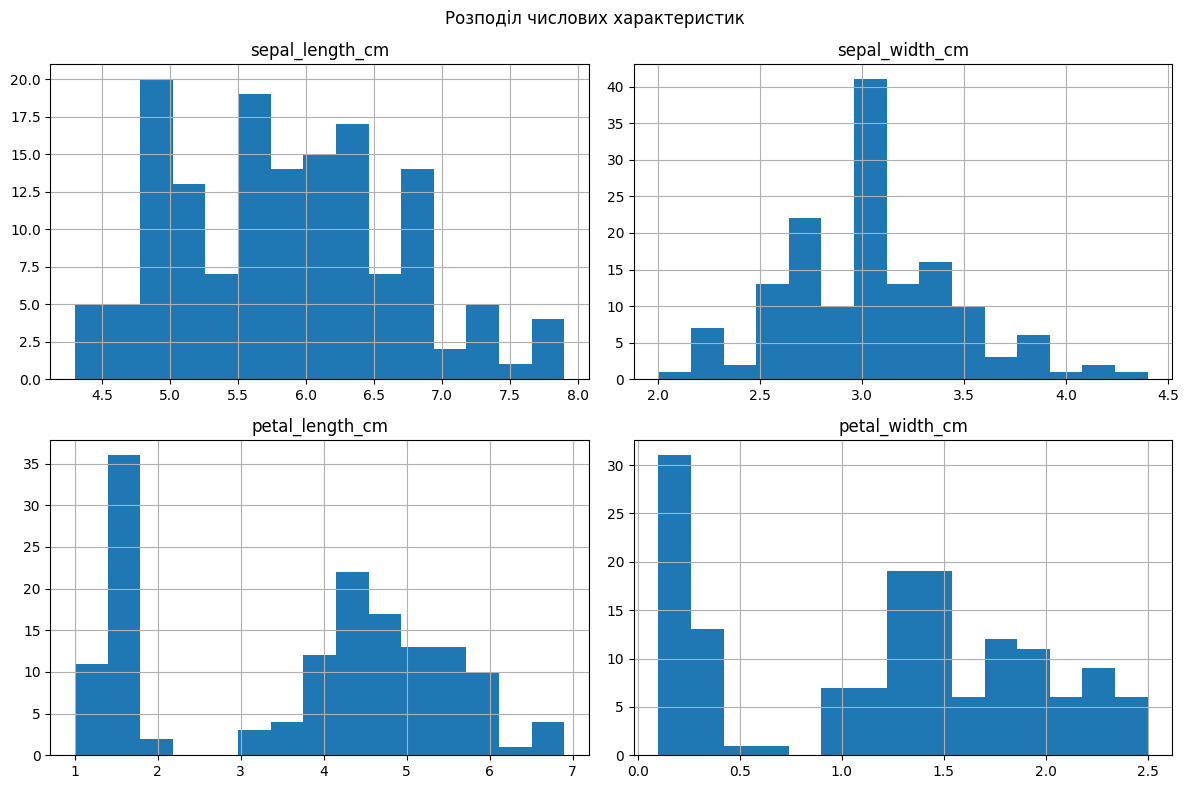

In [22]:
clean_df[numeric_columns].hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Розподіл числових характеристик")
plt.tight_layout()
plt.show()

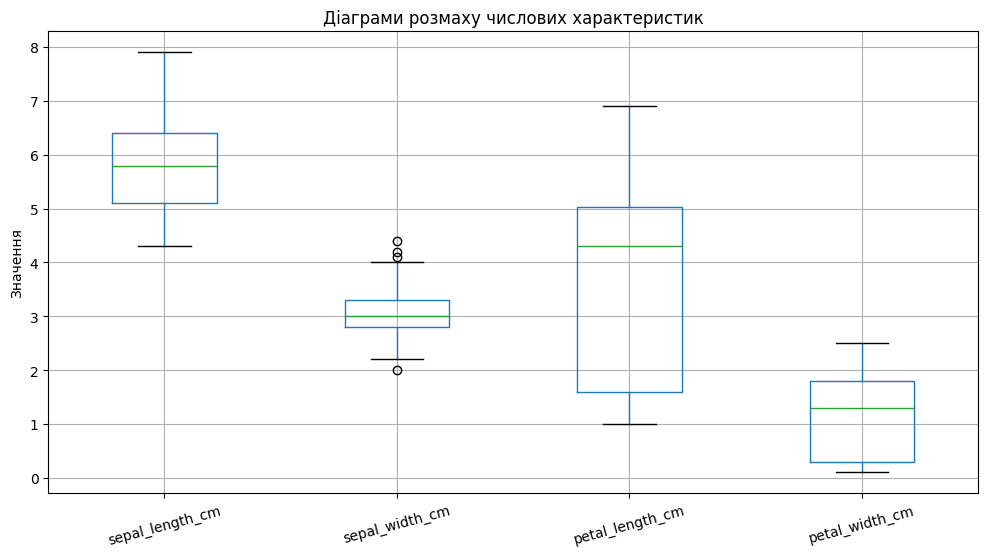

In [23]:
plt.figure(figsize=(12, 6))

clean_df[numeric_columns].boxplot()

plt.title("Діаграми розмаху числових характеристик")
plt.ylabel("Значення")
plt.xticks(rotation=15)
plt.show()

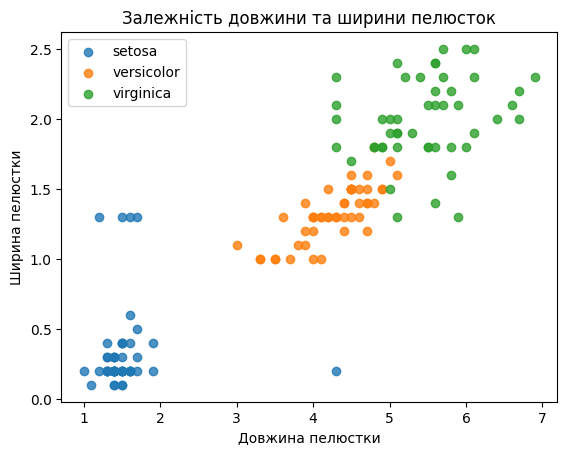

In [24]:
for species_name in clean_df["species"].unique():
    species_data = clean_df[clean_df["species"] == species_name]

    plt.scatter(
        species_data["petal_length_cm"],
        species_data["petal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини пелюсток")
plt.xlabel("Довжина пелюстки")
plt.ylabel("Ширина пелюстки")
plt.legend()
plt.show()

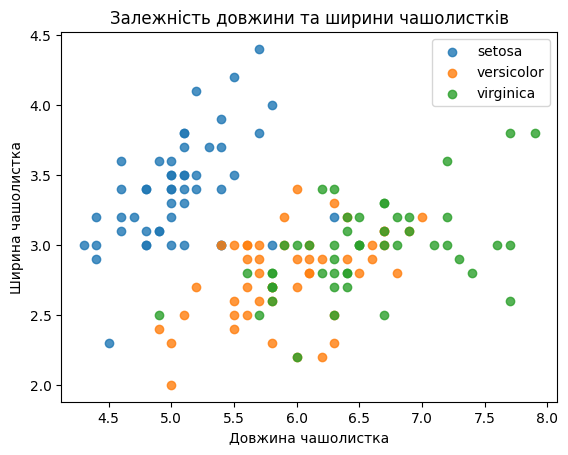

In [25]:
for species_name in clean_df["species"].unique():
    species_data = clean_df[clean_df["species"] == species_name]

    plt.scatter(
        species_data["sepal_length_cm"],
        species_data["sepal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини чашолистків")
plt.xlabel("Довжина чашолистка")
plt.ylabel("Ширина чашолистка")
plt.legend()
plt.show()

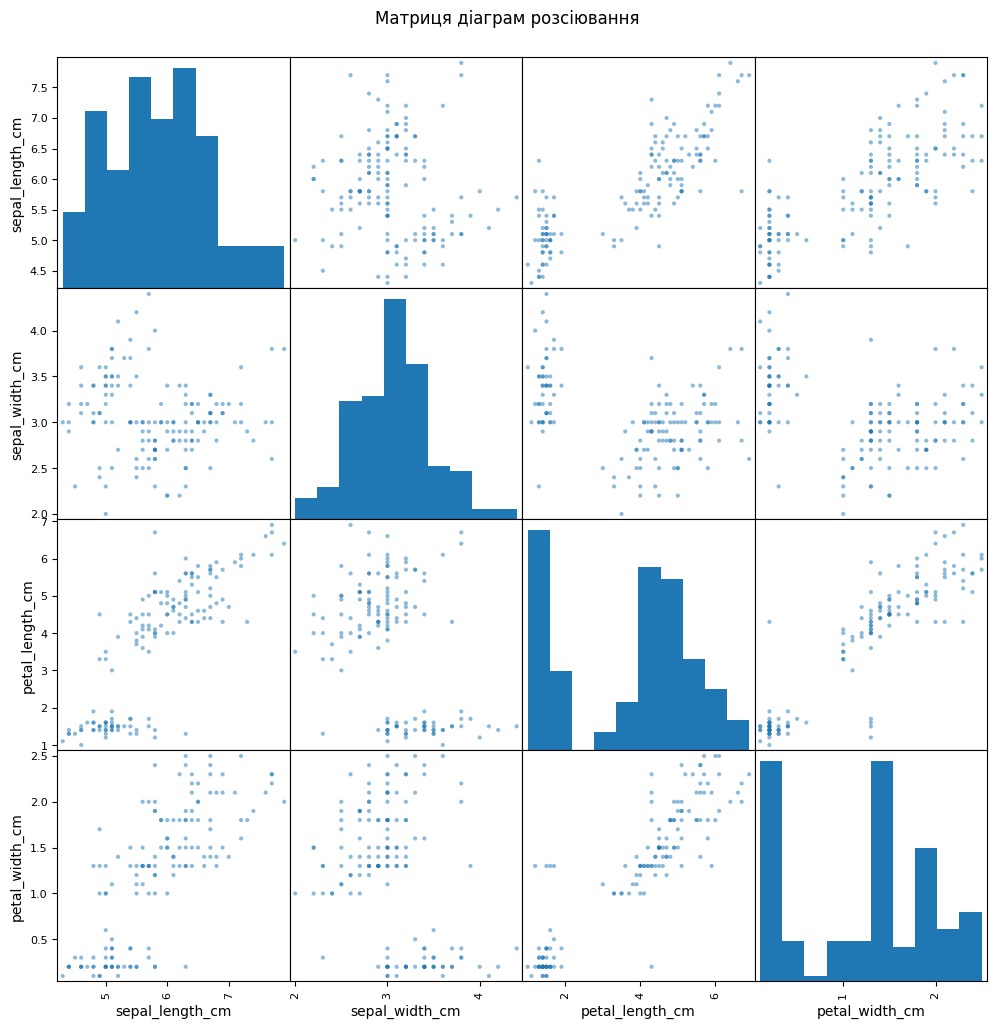

In [26]:
pd.plotting.scatter_matrix(
    clean_df[numeric_columns],
    figsize=(12, 12),
    diagonal="hist"
)

plt.suptitle("Матриця діаграм розсіювання", y=0.92)
plt.show()

Кореляційна матриця:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.000,-0.100,0.825,0.766
sepal_width_cm,-0.100,1.000,-0.397,-0.342
petal_length_cm,0.825,-0.397,1.000,0.914
petal_width_cm,0.766,-0.342,0.914,1.000


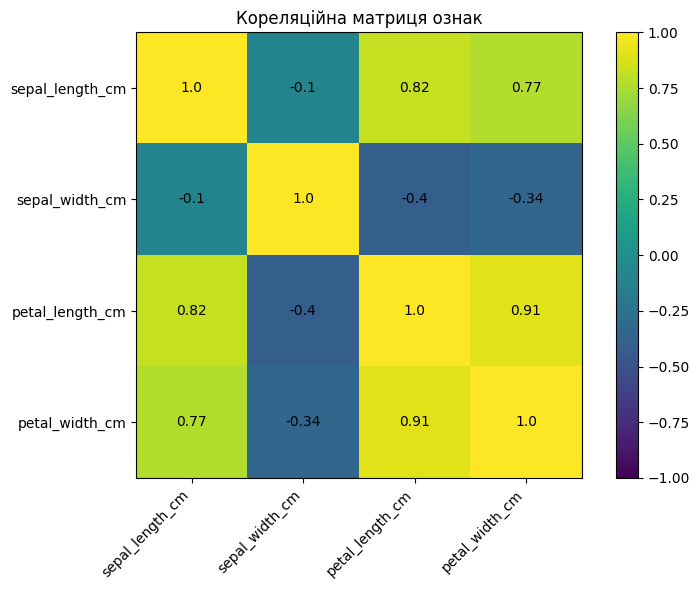

In [27]:
correlation_matrix = clean_df[numeric_columns].corr()

print("Кореляційна матриця:")
display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))

ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticklabels(numeric_columns)

for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        ax.text(
            j, i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.colorbar(image)
plt.title("Кореляційна матриця ознак")
plt.tight_layout()
plt.show()

Розподіл пристроїв вимірювання:


,count
measurement_device,
device_b,61
device_a,55
device_c,32


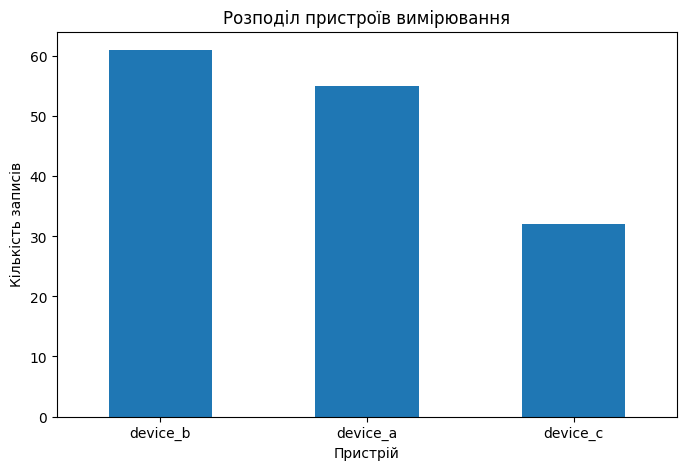

In [28]:
device_distribution = clean_df["measurement_device"].value_counts()

print("Розподіл пристроїв вимірювання:")
display(device_distribution)

device_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Розподіл пристроїв вимірювання")
plt.xlabel("Пристрій")
plt.ylabel("Кількість записів")
plt.xticks(rotation=0)
plt.show()

In [29]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=["measurement_device"],
    dtype=int
)

class_mapping = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}

encoded_df["species_code"] = encoded_df["species"].map(class_mapping)

print("Перші 5 рядків закодованих даних:")
display(encoded_df.head())

print("Розмір закодованого набору даних:", encoded_df.shape)

Перші 5 рядків закодованих даних:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c,species_code
0,5.1,3.5,1.4,0.2,setosa,0,0,1,0
1,5.8,3.0,1.4,0.2,setosa,0,1,0,0
2,6.3,3.2,1.3,0.2,setosa,0,0,1,0
3,4.6,3.1,1.5,0.2,setosa,1,0,0,0
4,5.0,3.6,1.4,0.2,setosa,0,1,0,0


Розмір закодованого набору даних: (148, 9)


In [30]:
X = encoded_df.drop(columns=["species", "species_code"])
y = encoded_df["species_code"]

print("Розмір матриці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

Розмір матриці ознак X: (148, 7)
Розмір цільової змінної y: (148,)


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки X_train:", X_train.shape)
print("Розмір тестової вибірки X_test:", X_test.shape)
print("Розмір навчальної вибірки y_train:", y_train.shape)
print("Розмір тестової вибірки y_test:", y_test.shape)

Розмір навчальної вибірки X_train: (118, 7)
Розмір тестової вибірки X_test: (30, 7)
Розмір навчальної вибірки y_train: (118,)
Розмір тестової вибірки y_test: (30,)


In [32]:
print("Розподіл класів у повному наборі:")
display(y.value_counts().sort_index())

print("Розподіл класів у навчальній вибірці:")
display(y_train.value_counts().sort_index())

print("Розподіл класів у тестовій вибірці:")
display(y_test.value_counts().sort_index())

Розподіл класів у повному наборі:


,count
species_code,
0,50
1,49
2,49


Розподіл класів у навчальній вибірці:


,count
species_code,
0,40
1,39
2,39


Розподіл класів у тестовій вибірці:


,count
species_code,
0,10
1,10
2,10


In [33]:
X_train_unstrat, X_test_unstrat, y_train_unstrat, y_test_unstrat = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=7
)

print("Розподіл класів без стратифікації:")
display(y_test_unstrat.value_counts().sort_index())

print("Розподіл класів зі стратифікацією:")
display(y_test.value_counts().sort_index())

Розподіл класів без стратифікації:


,count
species_code,
0,7
1,12
2,11


Розподіл класів зі стратифікацією:


,count
species_code,
0,10
1,10
2,10


In [34]:
preprocessing_summary = pd.DataFrame([
    {
        "stage": "raw_dirty",
        "rows": len(raw_df),
        "columns": raw_df.shape[1]
    },
    {
        "stage": "after_duplicates",
        "rows": len(raw_df.drop_duplicates()),
        "columns": raw_df.shape[1]
    },
    {
        "stage": "cleaned",
        "rows": len(clean_df),
        "columns": clean_df.shape[1]
    },
    {
        "stage": "train",
        "rows": len(X_train),
        "columns": X_train.shape[1]
    },
    {
        "stage": "test",
        "rows": len(X_test),
        "columns": X_test.shape[1]
    }
])

print("Підсумок обробки даних:")
display(preprocessing_summary)

Підсумок обробки даних:


,stage,rows,columns
0,raw_dirty,154,6
1,after_duplicates,150,6
2,cleaned,148,6
3,train,118,7
4,test,30,7


In [35]:
clean_df.to_csv(CLEANED_PATH, index=False)

X_train.to_csv(X_TRAIN_PATH, index=False)
X_test.to_csv(X_TEST_PATH, index=False)

y_train.to_frame(name="species_code").to_csv(
    Y_TRAIN_PATH,
    index=False
)

y_test.to_frame(name="species_code").to_csv(
    Y_TEST_PATH,
    index=False
)

preprocessing_summary.to_csv(SUMMARY_PATH, index=False)

with open(CLASS_MAPPING_PATH, "w", encoding="utf-8") as file:
    json.dump(class_mapping, file, ensure_ascii=False, indent=4)

print("Усі файли успішно збережено.")

Усі файли успішно збережено.


In [36]:
output_files = [
    SOURCE_PATH,
    DIRTY_PATH,
    CLEANED_PATH,
    X_TRAIN_PATH,
    X_TEST_PATH,
    Y_TRAIN_PATH,
    Y_TEST_PATH,
    SUMMARY_PATH,
    CLASS_MAPPING_PATH
]

print("Перевірка збережених файлів:")

for file_path in output_files:
    print(file_path.name, "-", "Збережено" if file_path.exists() else "Відсутній")

Перевірка збережених файлів:
iris.csv - Збережено
iris_dirty.csv - Збережено
iris_cleaned.csv - Збережено
X_train.csv - Збережено
X_test.csv - Збережено
y_train.csv - Збережено
y_test.csv - Збережено
preprocessing_summary.csv - Збережено
class_mapping.json - Збережено


In [37]:
assert clean_df.isna().sum().sum() == 0
assert clean_df.duplicated().sum() == 0

assert set(clean_df["species"].unique()) == {
    "setosa", "versicolor", "virginica"
}

assert set(clean_df["measurement_device"].unique()) == {
    "device_a", "device_b", "device_c"
}

assert all(
    pd.api.types.is_numeric_dtype(clean_df[column])
    for column in numeric_columns
)

assert (clean_df[numeric_columns] > 0).all().all()

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

assert list(X_train.columns) == list(X_test.columns)

assert set(y_train.unique()) == {0, 1, 2}
assert set(y_test.unique()) == {0, 1, 2}

assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("Усі перевірки успішно пройдено!")

Усі перевірки успішно пройдено!


### Порівняння середнього значення та медіани

Порівняння середнього значення та медіани показало, що для більшості ознак середнє значення трохи вище за медіану. Для ознаки petal_length_cm середнє значення нижче за медіану. Це може свідчити про асиметрію розподілу даних.

## Висновок

Під час практичної роботи було виконано аналіз та очищення набору даних Iris. Було виявлено та видалено дублікати, виправлено типи даних, оброблено пропущені й аномальні значення.

Також було виконано аналіз числових характеристик, побудовано графіки, досліджено кореляції та закодовано категоріальні ознаки.

Дані було розділено на навчальну та тестову вибірки у співвідношенні 80/20. Усі перевірки пройдено успішно.

Додатково було порівняно середнє значення та медіану числових ознак і розглянуто можливу асиметрію їх розподілу.